# Metro view of interleaving maps

This notebook starts with `Interleave(F, G)`, solves a larger loop–line example, and displays each map as a **pair**: the colored source graph next to its colored smoothed target. Corresponding source edges and target strands have the same color. Vertex labels use the same compact `s0`/`r0` notation as `ReebGraph.draw()`. The plots read the solved ILP matrices.

The design is inspired by [MetroSets](https://arxiv.org/abs/2008.09367), the [atmospheric rivers study](https://www.sci.utah.edu/~beiwang/publications/AR_BeiWang_2024.pdf), and the [contour tree uncertainty study](https://www.sci.utah.edu/~beiwang/publications/Uncertainty_CT_BeiWang_2026.pdf).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from cereeberus import Interleave
from cereeberus.data.ex_mappergraphs import line, torus
from cereeberus.draw.draw import _format_node_label
from cereeberus.draw.metro_maps import draw_map_pair, draw_interleaving_map_pairs

## Fit a larger loop–line example

`F` has a loop spanning levels 2–10; `G` is a line spanning levels 0–12. `Interleave.fit()` finds the smallest feasible `n` and stores the solved ILP in `result.assignment`. Seeds make the layout reproducible.

In [2]:
F = torus(0, 2, 10, 12, delta=1, seed=17)
G = line(0, 12, seed=5)
result = Interleave(F, G)
n = result.fit(max_n_for_error=5)
assignment = result.assignment
print(f"F: {len(F.nodes)} vertices, {len(F.edges)} edges")
print(f"G: {len(G.nodes)} vertices, {len(G.edges)} edges")
print(f"Fitted n = {n}; assignment loss = {assignment.loss()}")

F: 20 vertices, 20 edges
G: 13 vertices, 12 edges
Fitted n = 2; assignment loss = 0.0


## Graph overview

This is the six-graph view from `Assignment.draw_all_graphs`, with labels `s0` for mapper subdivisions and `r0` for smoothing vertices. The paired map plots below use the same names.

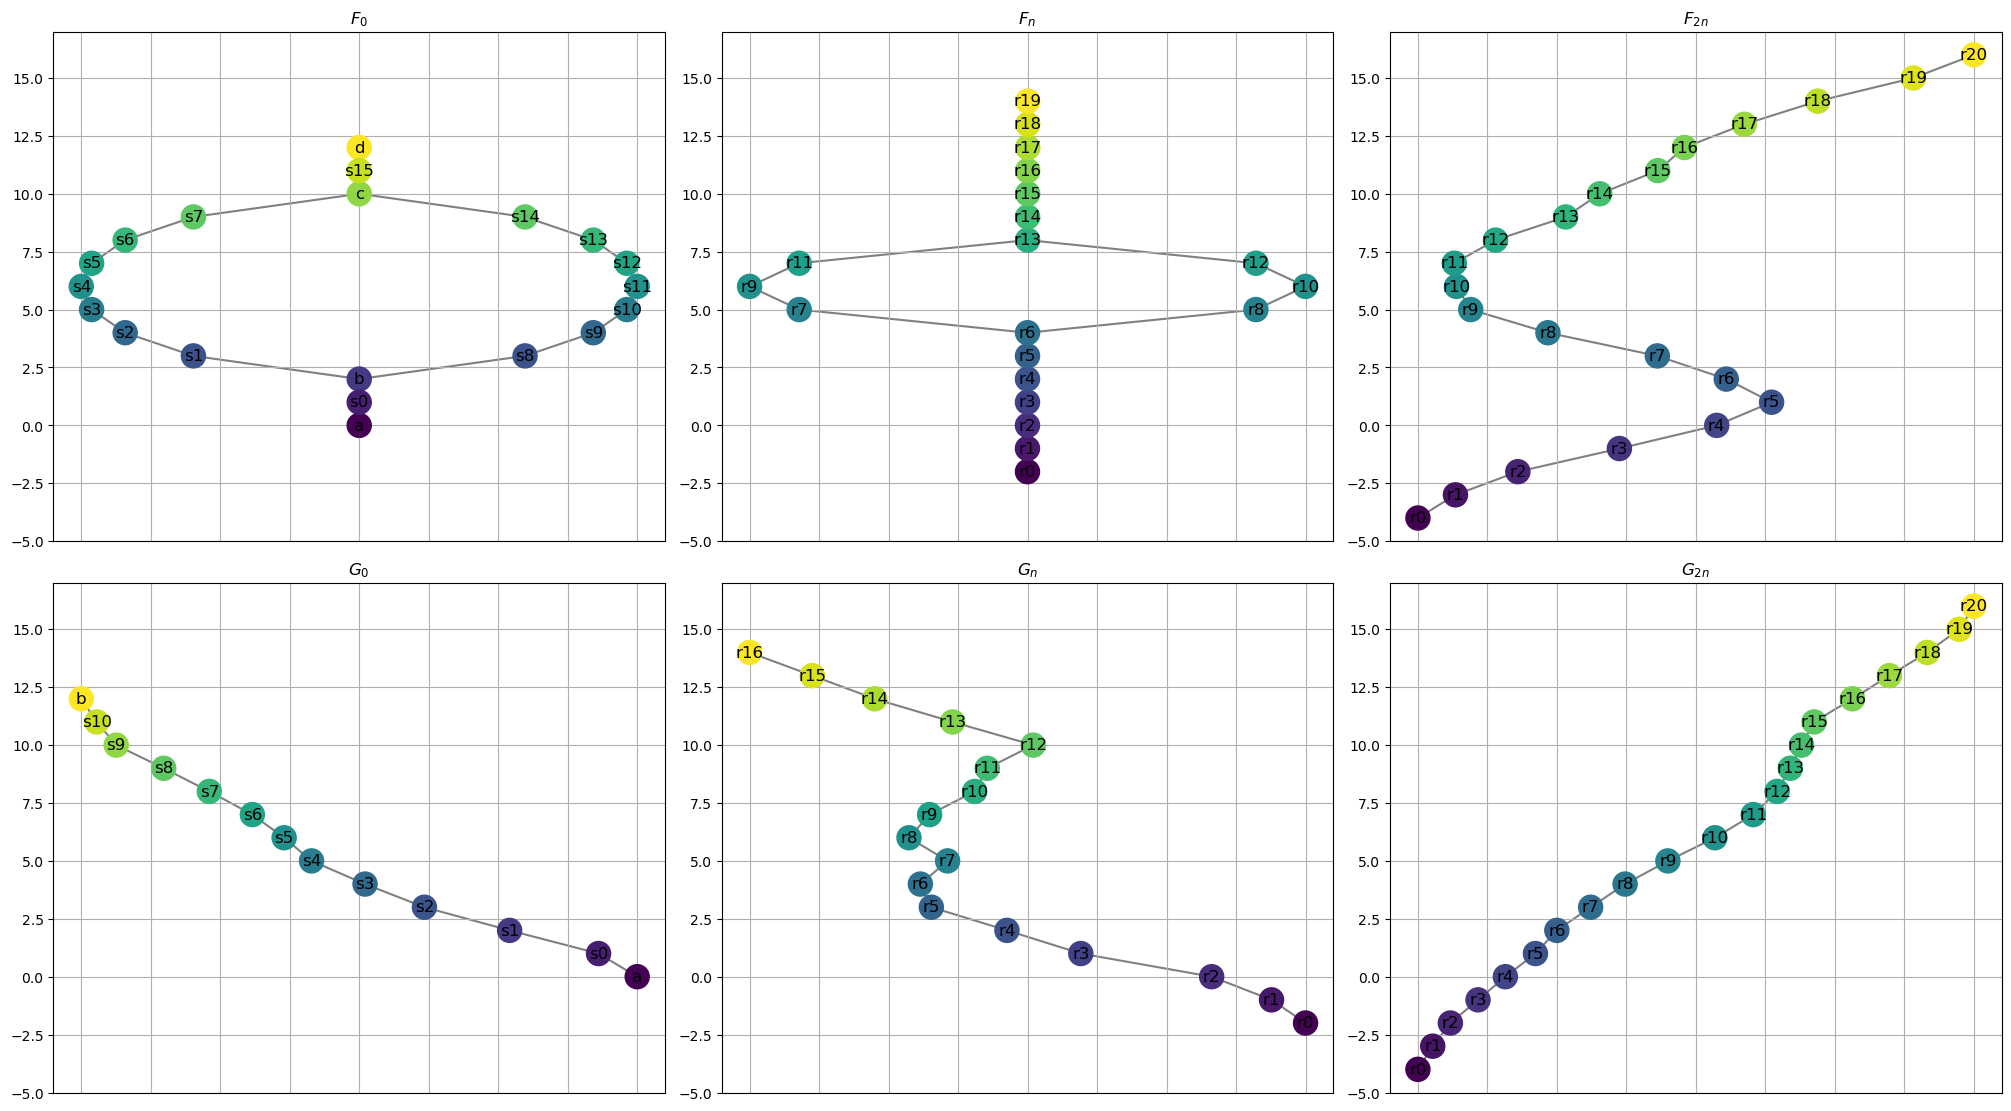

In [3]:
fig, axes = assignment.draw_all_graphs(figsize=(20, 11))
plt.show()

## Inspect the selected ILP rows

Every `1` in a matrix column selects a target row. The table uses the display names from `ReebGraph.draw()` so it can be checked against the figures.

In [4]:
def display_label(item):
    if isinstance(item, tuple) and len(item) >= 2 and item[0] not in ("mapper_subd", "reeb_auto"):
        label = f"{_format_node_label(item[0])}→{_format_node_label(item[1])}"
        return label if len(item) < 3 or item[2] == 0 else f"{label} ({item[2]})"
    return str(_format_node_label(item))

def selected_entries(matrix):
    records = []
    for level in matrix.get_all_block_indices():
        block = matrix[level]
        for column, source in enumerate(block.cols):
            for row, target in enumerate(block.rows):
                if block.array[row, column] > 0.5:
                    records.append({"level": level, "source": display_label(source), "target": display_label(target)})
    return pd.DataFrame(records)

for direction in ("phi", "psi"):
    for kind in ("V", "E"):
        print(f"{direction}, {kind}: source → target")
        display(selected_entries(getattr(result, direction)("0", kind)))

phi, V: source → target


,level,source,target
0,0,a,r2
1,1,s0,r3
2,2,b,r4
3,3,s1,r5
4,3,s8,r5
5,4,s2,r6
6,4,s9,r6
7,5,s3,r7
8,5,s10,r7
9,6,s4,r8


phi, E: source → target


,level,source,target
0,0,a→s0,r2→r3
1,1,s0→b,r3→r4
2,2,b→s1,r4→r5
3,2,b→s8,r4→r5
4,3,s1→s2,r5→r6
5,3,s8→s9,r5→r6
6,4,s2→s3,r6→r7
7,4,s9→s10,r6→r7
8,5,s3→s4,r7→r8
9,5,s10→s11,r7→r8


psi, V: source → target


,level,source,target
0,0,a,r2
1,1,s0,r3
2,2,s1,r4
3,3,s2,r5
4,4,s3,r6
5,5,s4,r8
6,6,s5,r10
7,7,s6,r12
8,8,s7,r13
9,9,s8,r14


psi, E: source → target


,level,source,target
0,0,a→s0,r2→r3
1,1,s0→s1,r3→r4
2,2,s1→s2,r4→r5
3,3,s2→s3,r5→r6
4,4,s3→s4,r6→r8
5,5,s4→s5,r8→r10
6,6,s5→s6,r10→r12
7,7,s6→s7,r12→r13
8,8,s7→s8,r13→r14
9,9,s8→s9,r14→r15


## Φ: F beside Gⁿ

The **left** panel is the source loop `F`. The **right** panel is `Gⁿ`; each colored strand lies on the destination edge chosen by the ILP. Matching colors identify the source edge. Station annotations show which source vertices land at target vertices.

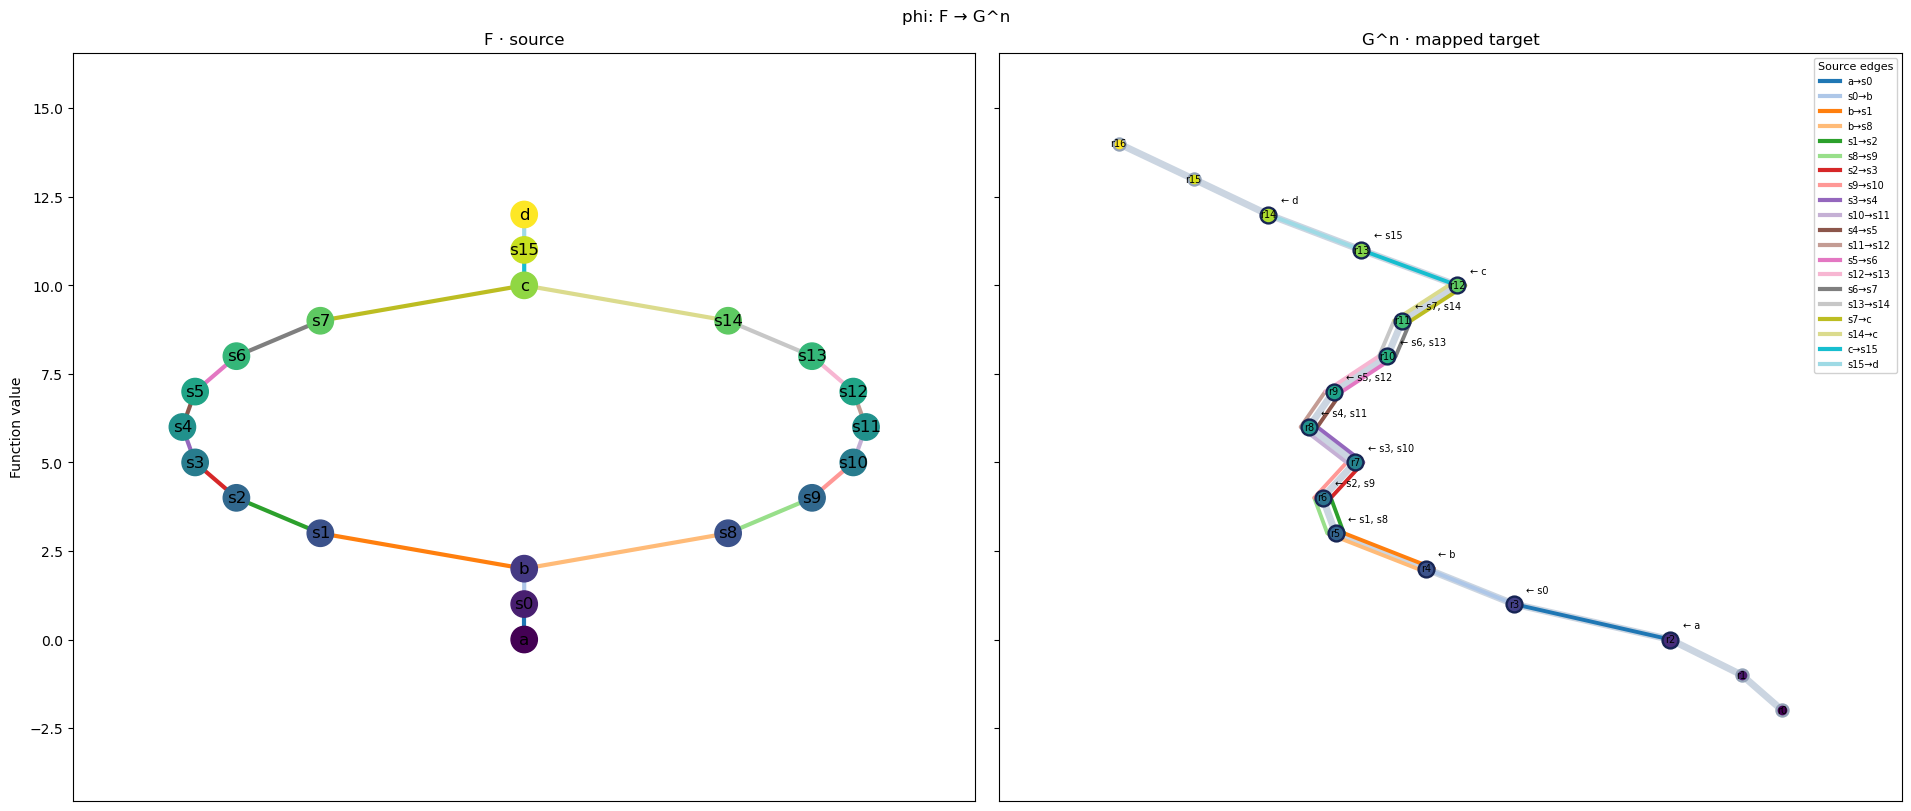

In [5]:
fig, axes = draw_map_pair(result, direction="phi", figsize=(19, 8), label_stations=True, max_legend=20)
plt.show()

## Ψ: G beside Fⁿ

Now `G` is the source, and `Fⁿ` is the destination. The same color is used for a source edge and its mapped strand within this pair.

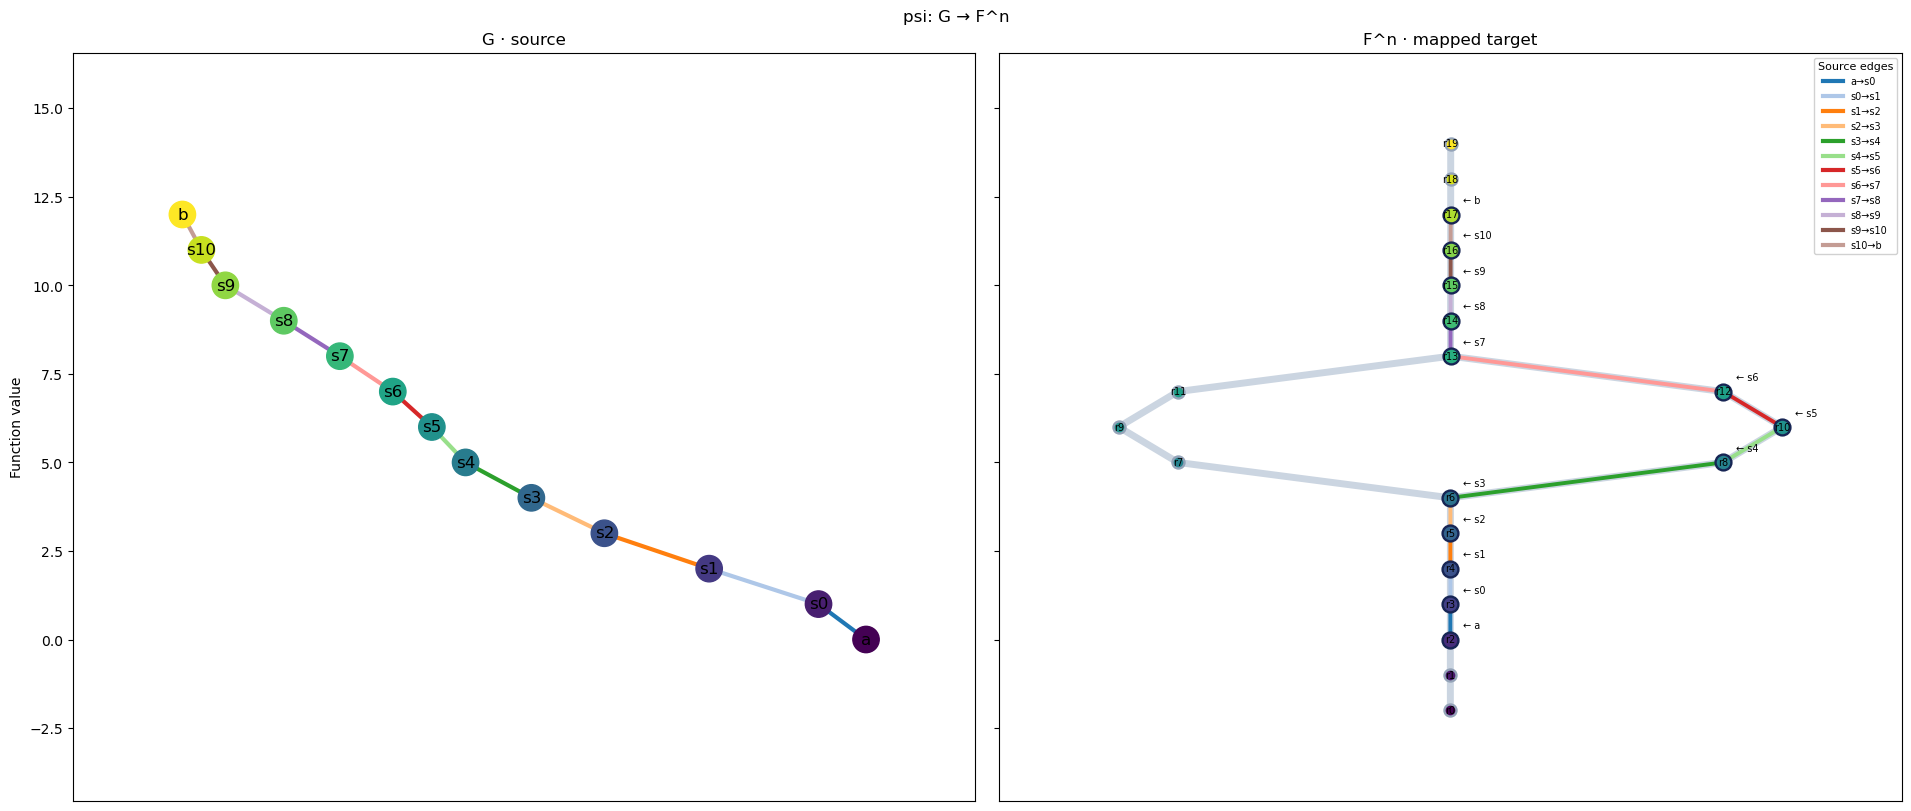

In [6]:
fig, axes = draw_map_pair(result, direction="psi", figsize=(19, 8), label_stations=True, max_legend=20)
plt.show()

## Both pairs together

The top row is `F → Gⁿ`; the bottom row is `G → Fⁿ`. This compact view is useful for comparing the two directions.

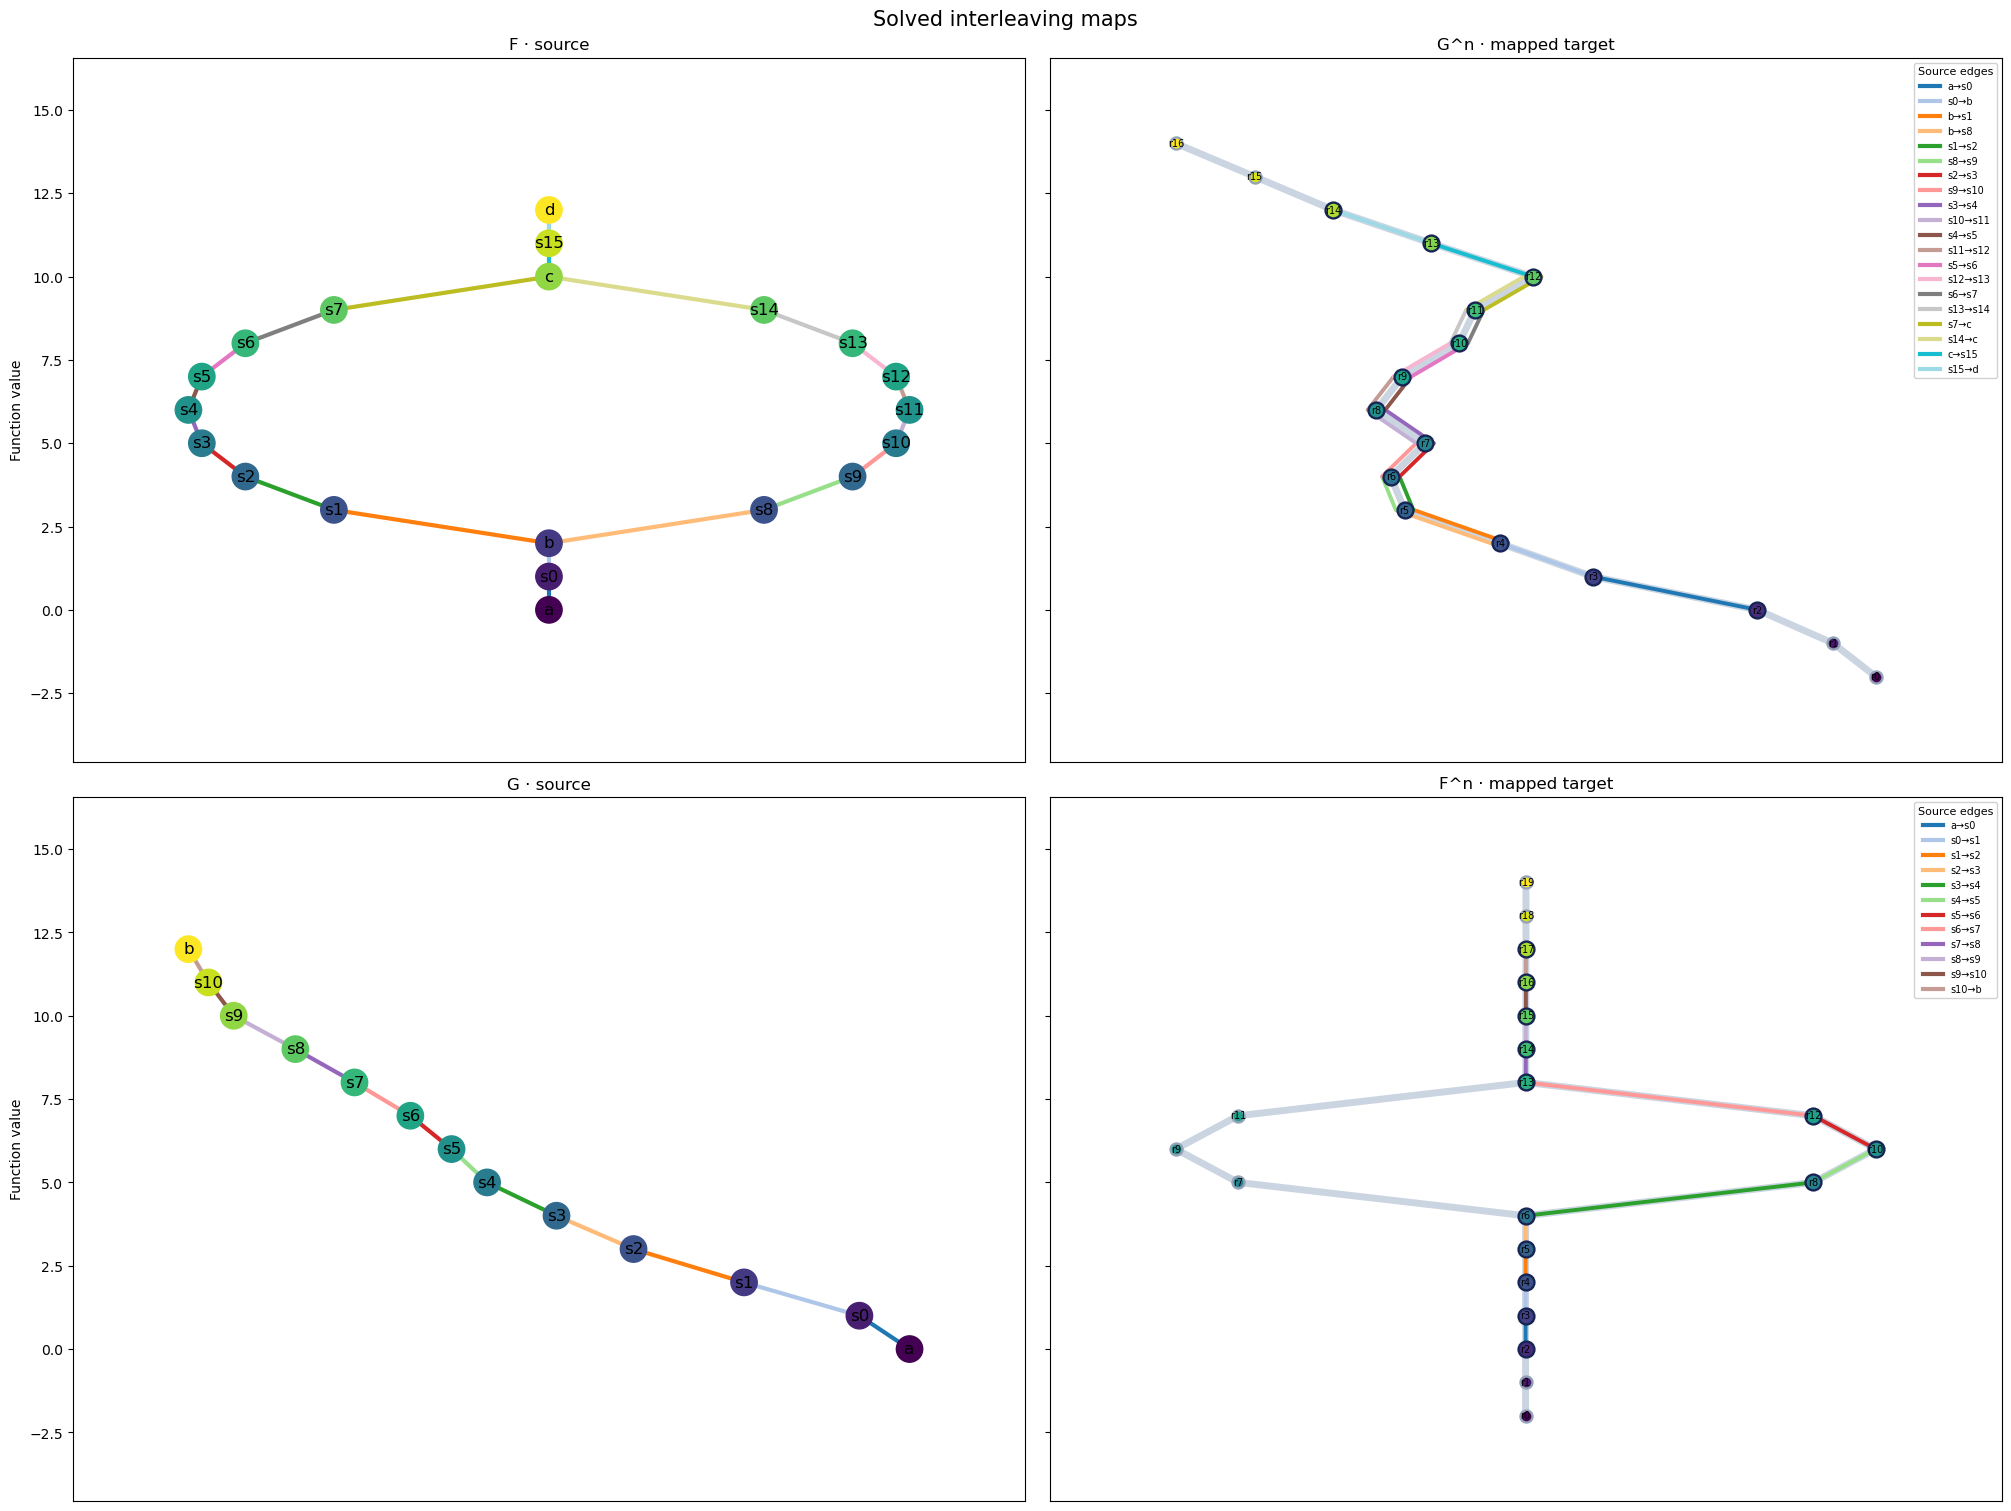

In [7]:
fig, axes = draw_interleaving_map_pairs(result, figsize=(20, 15), label_stations=False, max_legend=20)
plt.show()

## Auxiliary maps

Set `key="n"` to show `Fⁿ → G²ⁿ` or `Gⁿ → F²ⁿ`. The plotting functions do not rerun the ILP. Boundary columns with no selected target produce no strand.

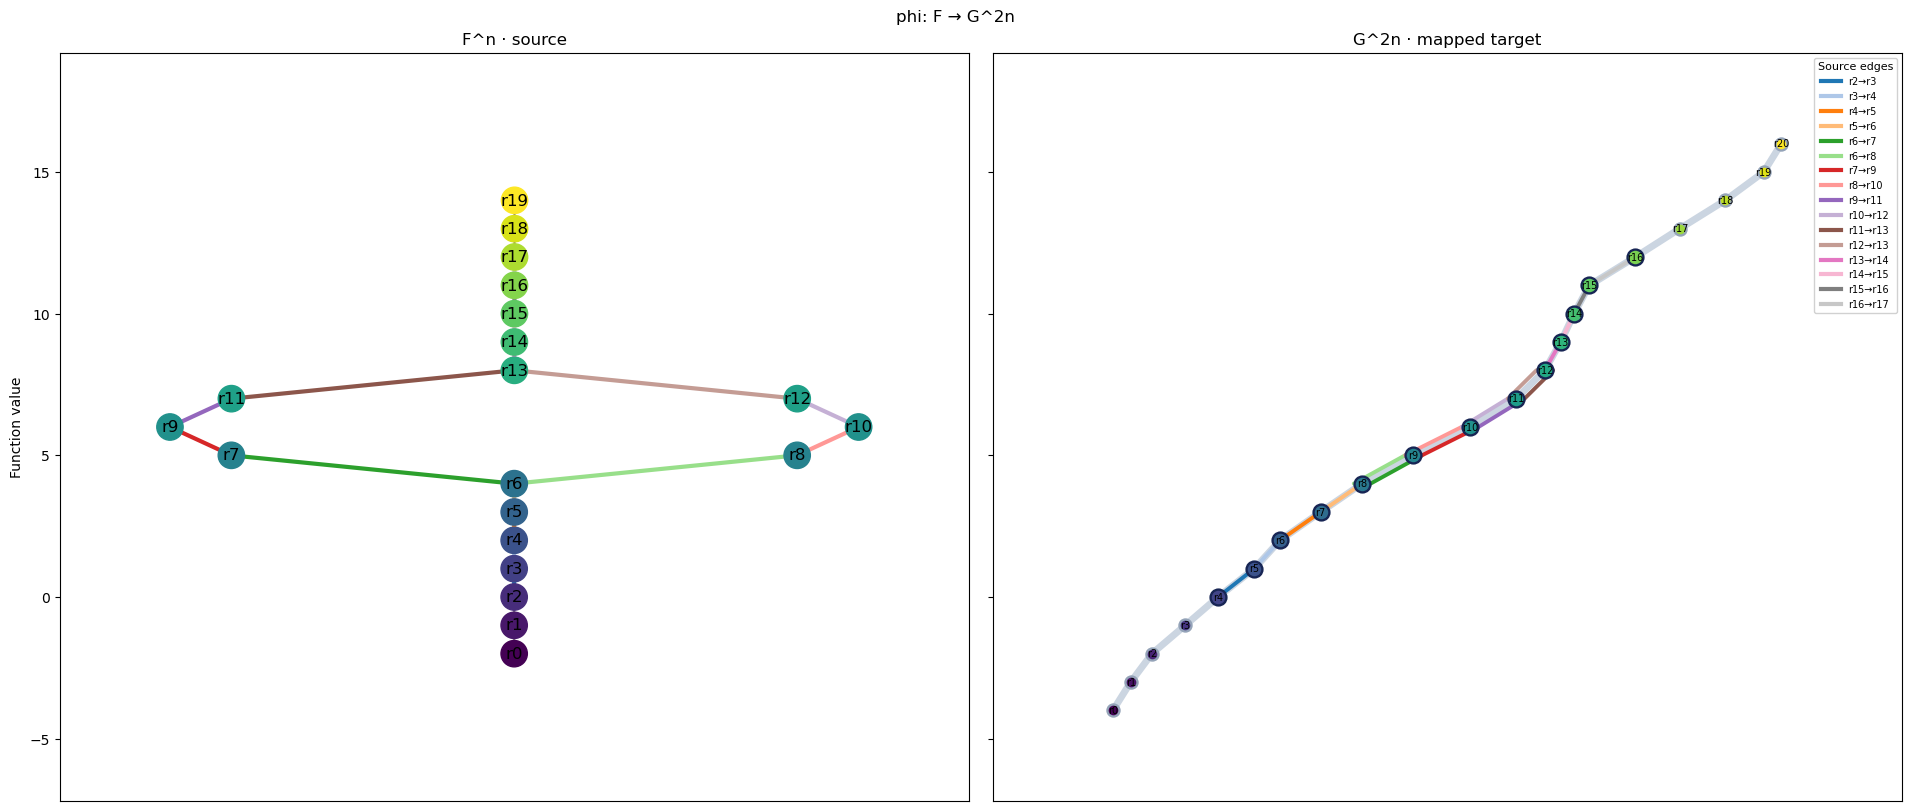

In [8]:
fig, axes = draw_map_pair(result, direction="phi", key="n", figsize=(19, 8), label_stations=False, max_legend=20)
plt.show()

## Try your own graphs

Replace `F` and `G` above with your own Mapper graphs, call `result = Interleave(F, G); result.fit()`, then pass `result` to `draw_map_pair`. The color correspondence is per source edge. This view does not infer full paths or uncertainty measures.